# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북의 목표는 그래프를 많이 만드는 것이 아닙니다. **분석 질문에 맞는 그래프를 선택하고, 그래프에 들어간 데이터 범위와 수치를 검증하며, 그래프가 보여 주는 사실과 보여 주지 못하는 것을 구분하는 것**이 핵심입니다.

금액성 그래프는 기본적으로 `order_status == "completed"` 범위를 사용합니다. `line_total`은 주문 상세 한 행의 `quantity × unit_price`이며 회계상 순매출로 단정하지 않습니다.

## 제출 정보
- 이름: 전해린
- GitHub ID: Haerin03
- 작성일: 2026.10.14
- 최종 Notebook URL: https://github.com/Haerin03/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb

## 0. 사용 방법

- 위에서부터 차례대로 실행합니다.
- 입력은 Chapter 05에서 만든 `data/processed/*_clean.csv`입니다.
- 파일이 없다면 프로젝트 루트에서 `python scripts/preprocess_data.py`를 먼저 실행합니다.
- 그래프를 보기 전에 **시각화용 집계 검증표**를 먼저 확인합니다.
- 대표 그래프마다 `관찰 → 해석 → 한계 → 다음 질문`을 Markdown 셀에 직접 작성합니다.
- 실제 실행 결과 숫자를 보고 작성하며 강의안의 예시를 정답처럼 사용하지 않습니다.

## 1. 질문에 맞는 그래프를 먼저 고릅니다

| 분석 질문 | 그래프 | 데이터 범위 |
| --- | --- | --- |
| 카테고리별 완료 주문 금액은 어떻게 다른가? | 막대그래프 | completed 주문 상세 |
| 월별 완료 주문 금액은 어떻게 변하는가? | 선그래프 | completed + 유효한 주문일 |
| 상품 가격은 어느 구간에 몰려 있는가? | 히스토그램 | 전체 상품 마스터 |
| 상품 가격과 완료 주문 판매 수량은 어떤 패턴인가? | 산점도 | completed 상품 집계 |
| 완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가? | 가로 막대그래프 | completed 고객 집계 |
| 주문 상태별 주문 수는 어떻게 다른가? | 막대그래프 | 전체 orders |

> 그래프 종류보다 먼저 **질문과 데이터 범위**를 고정합니다.

In [4]:
from pathlib import Path
import sys

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "chapter07" else CURRENT_DIR
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("현재 실행 위치:", CURRENT_DIR)
print("프로젝트 루트:", PROJECT_ROOT)
print("전처리 데이터 폴더:", PROCESSED_DIR)
print("그래프 저장 폴더:", FIGURE_DIR)

현재 실행 위치: c:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\chapter07
프로젝트 루트: c:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study
전처리 데이터 폴더: c:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\data\processed
그래프 저장 폴더: c:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\reports\figures


## 2. 검증된 시각화용 데이터를 준비합니다

공통 모듈은 그래프를 그리기 전에 다음을 검사합니다.

- 필수 컬럼
- PK 결측·중복
- `many_to_one` 병합
- 주문/상품 미매칭
- 숫자형 변환 실패
- `completed` 주문 범위
- 카테고리·상품·고객·월별 집계 총합

문제가 있으면 그래프를 만들기 전에 중단합니다.

In [5]:
from src.visualization import (
    prepare_visualization_data,
    setup_korean_font,
)

selected_font = setup_korean_font()
print("사용 한글 폰트:", selected_font or "자동 선택 실패 — 설치된 한글 폰트 확인 필요")

viz_data = prepare_visualization_data(PROCESSED_DIR)

products = viz_data["products"]
orders = viz_data["orders"]
completed_order_sales = viz_data["completed_order_sales"]
category_sales = viz_data["category_sales"]
monthly_sales = viz_data["monthly_sales"]
product_sales = viz_data["product_sales"]
customer_sales = viz_data["customer_sales"]
order_status = viz_data["order_status"]

print("완료 주문 상세 행:", len(completed_order_sales))
print(
    "월별 집계에서 제외되는 날짜 결측 완료 주문 상세:",
    len(viz_data["invalid_date_sales"]),
)

사용 한글 폰트: Malgun Gothic
완료 주문 상세 행: 474
월별 집계에서 제외되는 날짜 결측 완료 주문 상세: 0


In [6]:
viz_data["visualization_validation"]

,check,expected,actual,difference,passed
0,category_completed_amount,148990000.0,148990000.0,0.0,True
1,product_completed_amount,148990000.0,148990000.0,0.0,True
2,customer_completed_amount,148990000.0,148990000.0,0.0,True
3,monthly_completed_amount_valid_dates,148990000.0,148990000.0,0.0,True


### 검증 결과 기록

`passed`가 모두 `True`인지 확인한 뒤 아래 내용을 자신의 말로 작성합니다.

- 총합 검증 결과: 카테고리별, 상품별, 고객별, 월별 완료 주문 금액의 집계 결과를 검증한 결과, 모든 항목에서 expected와 actual이 148,990,000원으로 일치하였다. difference는 모두 0이었으며, passed 값도 모두 True로 확인되었다.
- 문제가 있었다면 원인: 총합 검증 과정에서 확인된 문제는 없었다. 또한 월별 집계에서 제외되는 날짜 결측 완료 주문 상세 행도 0건으로 확인되어, 주문일자 결측으로 인해 월별 금액이 누락되는 문제도 없었다.
- 시각화를 진행해도 된다고 판단한 이유: 완료 주문 상세 데이터를 기준으로 계산한 총 구매 금액과 카테고리별, 상품별, 고객별, 월별 집계 금액이 모두 동일하게 나타났다. 따라서 집계 과정에서 금액이 중복되거나 누락된 정황이 없다고 판단하였다. 특히 월별 집계에서도 날짜 결측으로 제외된 완료 주문이 없으므로, 검증된 집계값을 바탕으로 시각화를 진행해도 된다고 판단하였다.

## 3. 카테고리별 완료 주문 금액 — 막대그래프

범주별 크기 비교이므로 막대그래프를 사용합니다. 값 축은 0에서 시작합니다. 금액이 크다는 사실만으로 선호도가 높다고 단정하지 않습니다.

In [7]:
from src.visualization import plot_category_sales

category_sales[["category", "total_quantity", "completed_amount", "amount_ratio_pct"]]

,category,total_quantity,completed_amount,amount_ratio_pct
3,스포츠,295,31743000,21.31
5,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
1,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
0,도서,149,16389000,11.00
6,패션,111,10587000,7.11


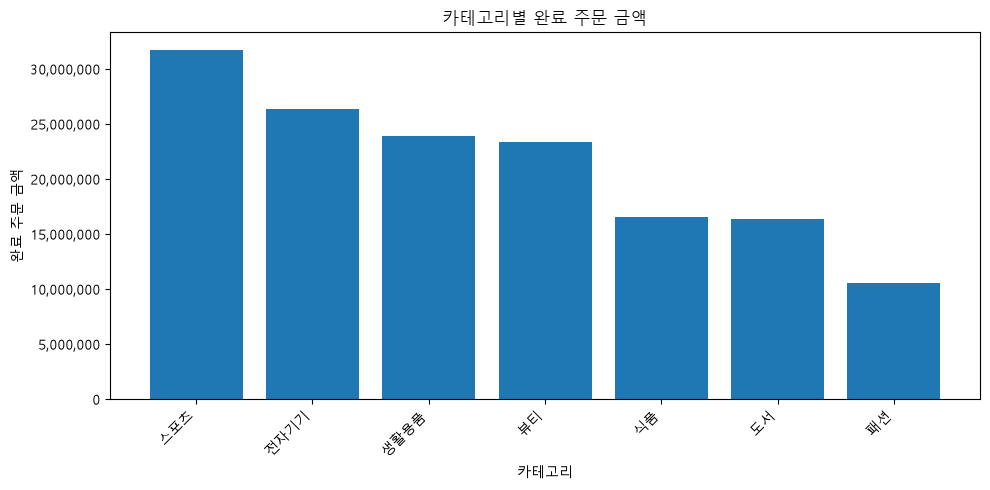

WindowsPath('c:/Users/82105/Desktop/대5/llm-data-analysis-study/llm-data-analysis-study/reports/figures/ch07_category_completed_amount_bar.png')

In [8]:
category_path = plot_category_sales(
    category_sales,
    FIGURE_DIR / "ch07_category_completed_amount_bar.png",
    show=True,
)
category_path

### 그래프 1 기록

- **관찰:** 실제 그래프와 집계표에서 직접 확인한 사실

카테고리별 완료 주문 금액을 비교한 결과, 스포츠가 31,743,000원으로 가장 높았고 전체 완료 주문 금액의 21.31%를 차지했다. 그다음은 전자기기 26,400,000원(17.72%), 생활용품 23,915,000원(16.05%), 뷰티 23,383,000원(15.69%) 순이었다. 반면 패션은 10,587,000원으로 가장 낮았으며 전체의 7.11%를 차지했다. 판매 수량도 스포츠가 295개로 가장 많았고, 패션은 111개로 가장 적었다.

- **해석:** 이 차이가 의미할 수 있는 내용

스포츠 카테고리는 완료 주문 금액과 판매 수량이 모두 가장 높게 나타나 다른 카테고리보다 전체 완료 주문 매출에서 차지하는 비중이 큰 것으로 볼 수 있다. 다만 카테고리별 금액 차이는 판매 수량뿐 아니라 상품 단가와 상품 구성의 영향을 함께 받을 수 있으므로, 단순히 스포츠 상품의 선호도가 가장 높다고 단정하기는 어렵다.
전자기기 카테고리의 판매수량은 259개에 비해 생활용품 카테고리의 판매수량은 272로 더 많지만, 완료 주문 금액은 전자기기 카테고리가 2,485,000원 더 높은 것으로 확인할 수 있다. 마찬가지로 도서 카테고리의 판매수량은 149개로 식품 카테고리의 판매수량 133개보다 많지만, 완료 주문 금액은 낮다. 이에 따라 판매수량과 완료 주문 금액은 비례하는 것은 아니며 별도의 요인에 영향을 받았음을 알 수 있다. 

- **한계:** 금액만으로 알 수 없는 것

현재 그래프는 카테고리별 총 구매 금액을 중심으로 비교한 것이므로, 각 카테고리의 평균 상품 단가, 상품 수, 주문 건수, 고객 수 등의 차이는 반영하지 않는다. 따라서 금액이 높게 나타난 이유가 많은 수량이 판매되었기 때문인지, 상대적으로 고가 상품이 많이 포함되어 있기 때문인지 이 그래프만으로는 확인할 수 없다.

- **다음 질문:** 판매 수량·단가·상품 수 중 무엇을 더 확인할 것인가?

카테고리별 완료 주문 금액 차이가 주로 판매 수량의 차이에서 발생하는지 확인하기 위해, 우선 카테고리별 총 판매 수량을 비교해 보고자 한다. 이후 카테고리별 평균 단가와 등록 상품 수도 함께 확인하면 금액 차이를 보다 구체적으로 해석할 수 있다.

## 4. 월별 완료 주문 금액 — 선그래프

시간 순서가 핵심인 질문이므로 선그래프를 사용합니다. 첫 달과 마지막 달이 완전한 한 달인지, 중간 월이 비어 있다면 실제 0인지 데이터 누락인지 확인합니다.

In [9]:
from src.visualization import plot_monthly_sales

monthly_sales[
    [
        "order_month",
        "completed_amount",
        "completed_order_count",
        "average_completed_order_amount",
    ]
]

,order_month,completed_amount,completed_order_count,average_completed_order_amount
0,2025-07,5869000,8,733625.0
1,2025-08,15621000,18,867833.0
2,2025-09,10190000,13,783846.0
3,2025-10,25766000,26,991000.0
4,2025-11,8812000,12,734333.0
5,2025-12,11501000,14,821500.0
6,2026-01,17423000,22,791955.0
7,2026-02,9749000,17,573471.0
8,2026-03,13429000,14,959214.0
9,2026-04,17553000,23,763174.0


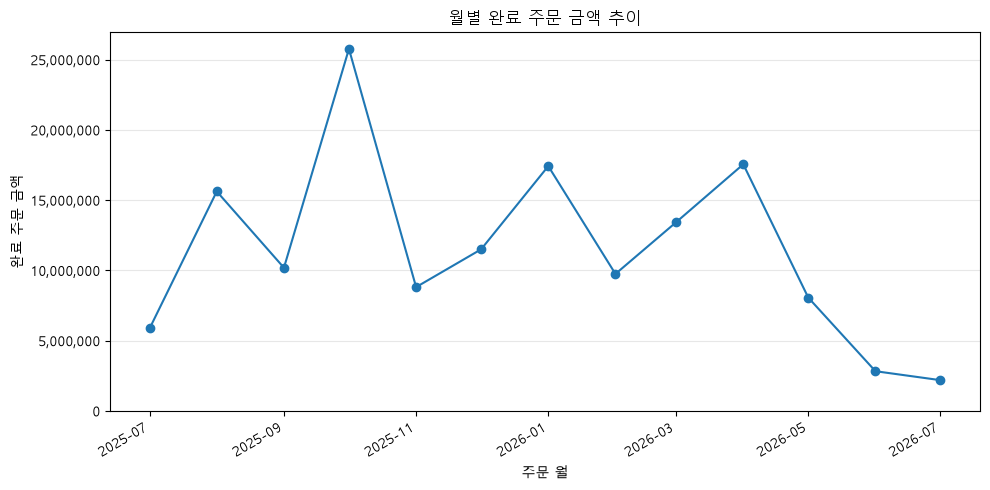

WindowsPath('c:/Users/82105/Desktop/대5/llm-data-analysis-study/llm-data-analysis-study/reports/figures/ch07_monthly_completed_amount_line.png')

In [10]:
monthly_path = plot_monthly_sales(
    monthly_sales,
    FIGURE_DIR / "ch07_monthly_completed_amount_line.png",
    show=True,
)
monthly_path

### 그래프 2 기록

- **관찰:** 증가·감소 또는 변곡이 실제로 보이는가?

월별 완료 주문 금액은 일정하게 증가하거나 감소하기보다 월마다 변동하는 모습을 보였다. 2025년 10월의 완료 주문 금액이 25,766,000원으로 가장 높았고, 이후 11월에는 8,812,000원으로 크게 감소했다. 2026년 1월과 4월에는 각각 17,423,000원과 17,553,000원으로 다시 높아졌으며, 2026년 5월 이후에는 감소하여 7월에는 2,188,000원으로 가장 낮게 나타났다.

- **해석:** 주문 수와 평균 주문 금액 중 무엇이 함께 변했는가?

완료 주문 금액이 높았던 2025년 10월에는 완료 주문 수도 26건으로 전체 기간 중 가장 많았고, 평균 완료 주문 금액도 991,000원으로 비교적 높은 수준이었다. 따라서 해당 월의 높은 매출은 주문 수 증가와 주문당 평균 금액이 함께 영향을 준 것으로 볼 수 있다. 반면 2026년 7월은 평균 주문 금액이 1,094,000원으로 가장 높았지만 완료 주문 수가 2건에 불과하여 총 완료 주문 금액은 낮게 나타났다. 이를 통해 월별 총 금액은 평균 주문 금액뿐 아니라 주문 건수의 영향을 크게 받는다는 점을 확인할 수 있다.

- **한계:** 프로모션·계절성 등 현재 데이터에 없는 원인을 단정하지 않았는가?

현재 데이터에서는 월별 완료 주문 금액, 주문 수, 평균 주문 금액의 변화는 확인할 수 있지만, 이러한 변화가 프로모션, 계절성, 할인 행사, 특정 상품 출시 등 어떤 원인에서 발생했는지는 확인할 수 없다. 특히 2025년 10월의 높은 금액이나 2026년 5~7월의 감소를 특정 이벤트나 계절적 요인 때문이라고 단정해서는 안 된다. 또한 마지막 월인 2026년 7월이 완전한 한 달치 데이터인지도 추가 확인이 필요하다.

- **다음 질문:** 추가로 확인할 지표는 무엇인가?

월별 완료 주문 금액 변화가 어떤 요소와 함께 나타나는지 확인하기 위해 월별 완료 주문 수, 평균 주문 금액, 판매 수량, 카테고리별 매출 구성을 추가로 비교할 필요가 있다. 특히 총 금액 변화가 주문 건수의 변화 때문인지, 특정 카테고리 또는 고가 상품의 판매 증가 때문인지 확인해 볼 수 있다.

## 5. 상품 가격 분포 — 히스토그램

상품 가격은 상품 마스터의 속성이므로 주문 상태와 무관하게 전체 상품을 봅니다. `bins` 값에 따라 모양이 달라질 수 있으므로 구간 수 하나만 보고 이상값을 확정하지 않습니다.

In [11]:
from src.visualization import plot_product_price_hist

products["price"].describe()

count       100.000000
mean     110040.000000
std       56433.910574
min        5000.000000
25%       65750.000000
50%      112000.000000
75%      161000.000000
max      200000.000000
Name: price, dtype: float64

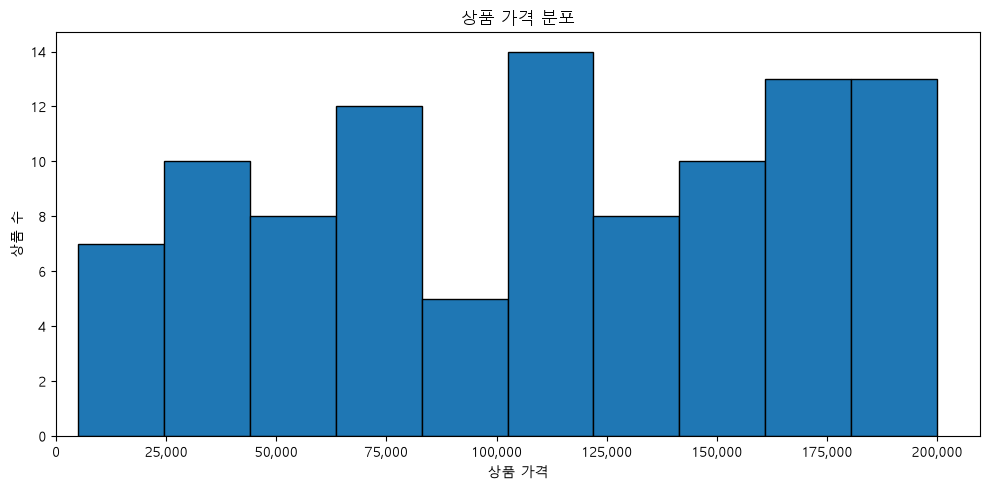

WindowsPath('c:/Users/82105/Desktop/대5/llm-data-analysis-study/llm-data-analysis-study/reports/figures/ch07_product_price_hist.png')

In [22]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=10,
)
price_hist_path

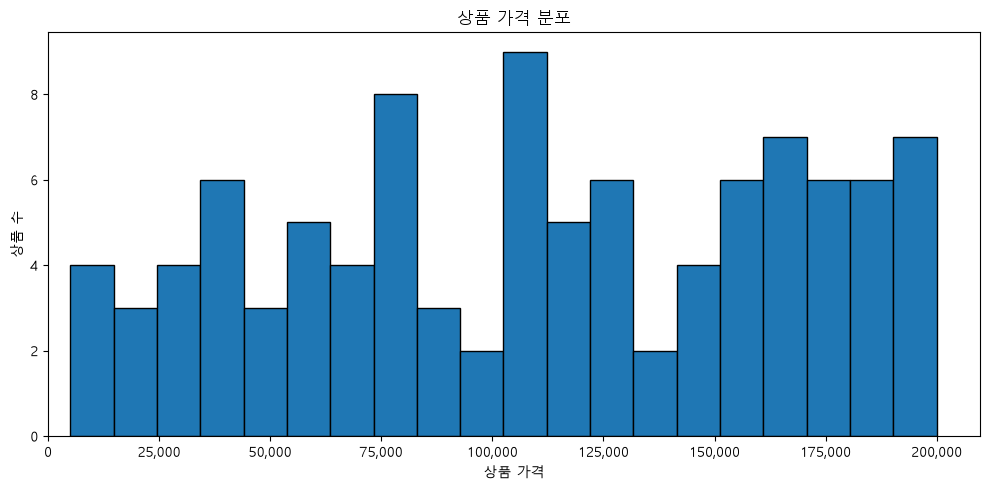

WindowsPath('c:/Users/82105/Desktop/대5/llm-data-analysis-study/llm-data-analysis-study/reports/figures/ch07_product_price_hist.png')

In [23]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=20,
)
price_hist_path

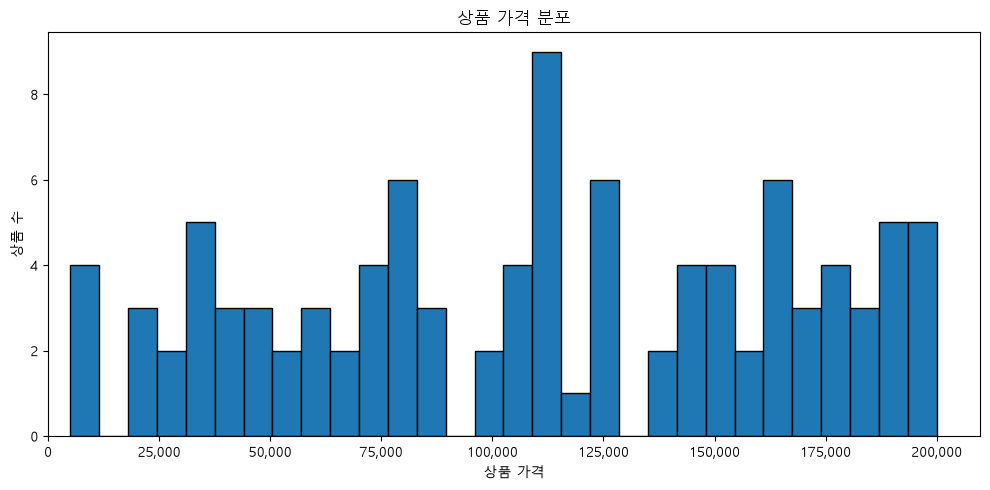

WindowsPath('c:/Users/82105/Desktop/대5/llm-data-analysis-study/llm-data-analysis-study/reports/figures/ch07_product_price_hist.png')

In [21]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=30,
)
price_hist_path

### bins 비교 실습

`bins=10`, `20`, `30`으로 바꾸어 같은 데이터가 어떻게 다르게 보이는지 비교합니다.

- 어떤 공통 패턴이 유지되는가?

bins=10, 20, 30으로 변경해도 상품 가격이 약 5,000원에서 200,000원 사이에 분포하고 있다는 점은 동일하게 나타난다. 또한 가격이 특정 한 구간에만 집중되어 있기보다는 전체 가격 범위에 비교적 넓게 분포하고 있으며, 약 100,000원 전후와 160,000~200,000원 구간에서도 상품이 여러 개 존재한다는 점은 공통적으로 확인된다. 더불어 모두 100,000원 대 상품이 가장 많은 것으로 나타난다.

- 어떤 인상은 bins 선택에 따라 달라지는가?

bins=10에서는 가격 구간이 넓게 묶이기 때문에 전체적인 분포 형태를 비교적 단순하게 확인할 수 있다. 반면 bins=20에서는 가격대별 차이가 더 세분화되어 약 100,000~120,000원 부근에서 상대적으로 많은 상품이 존재하는 모습이 더 뚜렷하게 보인다. bins=30에서는 구간이 더 잘게 나뉘어 세부적인 가격 분포를 확인할 수 있지만, 일부 구간이 비어 있거나 막대 높이가 크게 달라 보여 분포가 더 불규칙한 것처럼 느껴질 수 있다.

- 해석:
같은 100개의 상품 가격 데이터를 사용하더라도 bins 수에 따라 그래프에서 강조되는 패턴이 달라질 수 있음을 확인했다. 따라서 특정 가격 구간에 상품이 집중되어 있다고 판단할 때는 하나의 bins 설정만 보고 결론을 내리기보다 여러 구간 수를 비교할 필요가 있다. 

- 한계: 
히스토그램은 상품 가격 자체의 분포만 보여 주므로 실제로 어떤 가격대의 상품이 많이 판매되었는지는 알 수 없다. 또한 bins 설정에 따라 특정 구간이 강조되거나 분포가 더 불규칙하게 보일 수 있으므로, 그래프의 모양만으로 가격대의 명확한 군집이 존재한다고 단정하기 어렵다.

## 6. 상품 가격과 완료 주문 판매 수량 — 산점도

한 점은 상품 하나입니다. 관계가 보여도 **가격이 판매 수량의 원인**이라고 단정하지 않습니다.

In [13]:
from src.visualization import plot_price_quantity_scatter

product_sales[["price", "completed_quantity", "completed_amount"]].head(10)

,price,completed_quantity,completed_amount
39,163000,35,5705000
11,175000,25,4375000
8,193000,20,3860000
70,189000,20,3780000
69,161000,23,3703000
66,140000,26,3640000
78,165000,22,3630000
10,115000,31,3565000
20,112000,29,3248000
86,103000,30,3090000


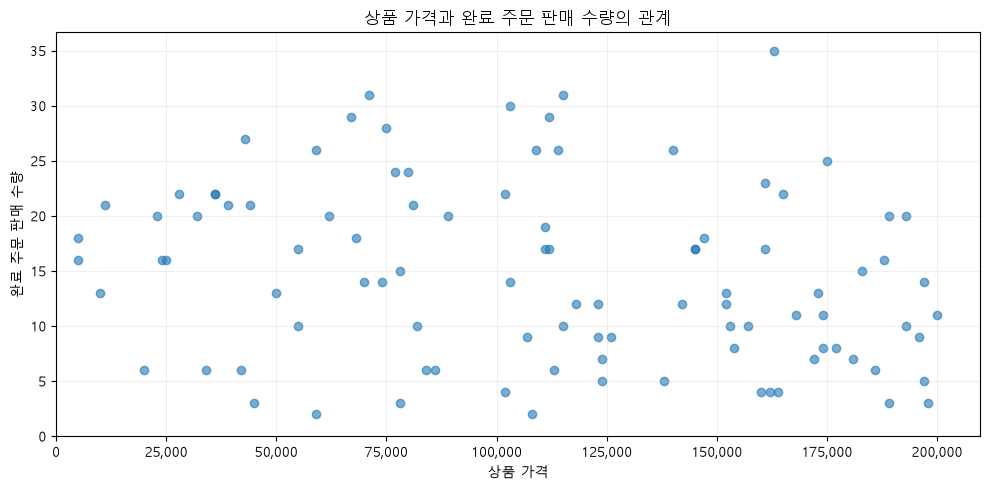

WindowsPath('c:/Users/82105/Desktop/대5/llm-data-analysis-study/llm-data-analysis-study/reports/figures/ch07_price_completed_quantity_scatter.png')

In [14]:
scatter_path = plot_price_quantity_scatter(
    product_sales,
    FIGURE_DIR / "ch07_price_completed_quantity_scatter.png",
    show=True,
)
scatter_path

### 그래프 3 기록

- **관찰:** 점들이 어떤 범위에 분포하는가?

상품 가격은 약 5,000원에서 200,000원 사이에 분포하고, 완료 주문 판매 수량은 대체로 2개에서 35개 사이에 분포한다. 전체적으로 점들이 넓게 퍼져 있으며, 특정 가격대에만 판매 수량이 집중되어 있지는 않다. 예를 들어 163,000원 상품은 완료 주문 판매 수량이 35개로 비교적 높았지만, 비슷한 고가 구간에서도 판매 수량이 5~20개 수준인 상품들이 함께 존재한다.

- **해석:** 관계가 있어 보이는가, 뚜렷하지 않은가?

상품 가격이 높아질수록 판매 수량이 일정하게 증가하거나 감소하는 뚜렷한 패턴은 보이지 않는다. 따라서 현재 산점도만으로는 상품 가격과 완료 주문 판매 수량 사이에 강한 관계가 있다고 보기 어렵다. 일부 고가 상품에서도 높은 판매 수량이 나타나고, 반대로 낮은 가격대에서도 판매 수량이 낮은 상품이 존재하므로 가격만으로 판매 수량을 설명하기에는 한계가 있다.

- **한계:** 카테고리·할인·노출·재고 등 다른 변수를 확인하지 않은 상태에서 무엇을 말할 수 없는가?

현재 그래프는 상품 가격과 완료 주문 판매 수량 두 변수만 비교한 것이므로, 카테고리, 할인 여부, 프로모션, 상품 노출 정도, 재고 수준, 판매 기간 등의 영향을 반영하지 못한다. 따라서 특정 상품이 많이 팔린 이유나 가격이 판매 수량에 직접적인 영향을 주었다고 단정할 수 없다. 또한 상품마다 판매 가능 기간이나 노출 기회가 달랐다면 동일한 기준으로 단순 비교하기 어려울 수 있다.

- **다음 질문:** 어떤 변수를 추가하면 관계를 더 잘 이해할 수 있는가?

상품 가격과 판매 수량의 관계를 더 잘 이해하기 위해 상품 카테고리를 추가로 확인하는 것이 좋다. 카테고리별로 가격대와 판매 수량의 관계가 다르게 나타나는지 비교하면 전체 산점도에서는 보이지 않았던 패턴을 확인할 수 있다. 가능하다면 이후 할인 여부, 판매 기간, 재고 등의 변수도 함께 분석하는 것이 필요하다.

## 7. 완료 주문 구매 금액 상위 고객 — 익명 가로 막대그래프

공개 그래프에서는 고객 이름이나 원본 고객 ID를 직접 표시하지 않고 **순위 기반 익명 라벨**을 사용합니다. Top 10은 전체 고객 분포가 아니라 일부 고객만 보여 줍니다.

In [15]:
from src.visualization import plot_top_customers

customer_sales[
    ["customer_id", "completed_order_count", "completed_amount", "average_completed_order_amount"]
].head(10)

,customer_id,completed_order_count,completed_amount,average_completed_order_amount
76,117,5,4100000,820000.0
62,102,4,3996000,999000.0
51,83,4,3880000,970000.0
21,30,5,3590000,718000.0
29,40,4,3523000,880750.0
13,20,2,3191000,1595500.0
0,3,2,3178000,1589000.0
70,111,3,3153000,1051000.0
42,66,4,3093000,773250.0
97,147,2,2990000,1495000.0


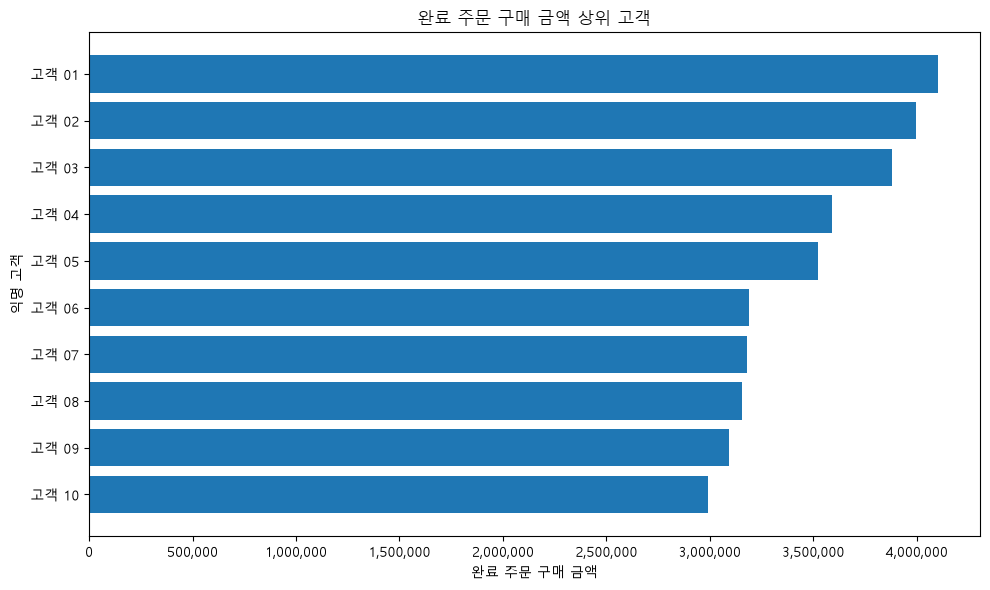

WindowsPath('c:/Users/82105/Desktop/대5/llm-data-analysis-study/llm-data-analysis-study/reports/figures/ch07_top_customers_anonymized_barh.png')

In [16]:
top_customer_path = plot_top_customers(
    customer_sales,
    FIGURE_DIR / "ch07_top_customers_anonymized_barh.png",
    show=True,
    top_n=10,
)
top_customer_path

### 해석 주의

구매 금액이 높다고 바로 '충성 고객'이라고 부르지 않습니다.

- 반복 주문 횟수는 많은가?

상위 구매 고객의 완료 주문 횟수는 2~5건으로 차이가 있었다. 따라서 구매 금액이 높다고 해서 반드시 반복 주문 횟수가 많은 것은 아니었다.

- 한 번의 큰 주문 때문인가?

일부 고객은 주문 횟수가 2건에 불과하지만 평균 주문 금액이 약 150만 원 이상으로 높았다. 따라서 높은 누적 구매 금액이 반복 구매보다는 소수의 고액 주문에서 나온 경우도 있다고 볼 수 있다.

- 평균 주문 금액은 어떤가?

상위 고객의 평균 주문 금액은 약 718,000원에서 1,595,500원까지 차이가 컸다. 즉, 상위 고객군 내부에서도 자주 구매하는 고객과 한 번에 큰 금액을 구매하는 고객의 패턴이 서로 다를 수 있다.

- 분석 기간이 충분한가?

현재 결과만으로는 분석 기간이 고객의 장기적인 구매 행동을 판단하기에 충분한지 확정하기 어렵다. 따라서 상위 구매 고객을 곧바로 충성 고객이라고 판단하기보다는 더 긴 기간의 반복 구매 여부와 최근 구매 시점 등을 추가로 확인할 필요가 있다.

## 8. 전체 주문 상태 — 막대그래프

이 그래프만 전체 주문을 사용합니다. 상태별 규모는 보여 주지만 취소·환불의 원인을 설명하지 않습니다.

In [17]:
from src.visualization import plot_order_status

order_status

,order_status,order_count
0,completed,184
1,cancelled,64
2,refunded,52


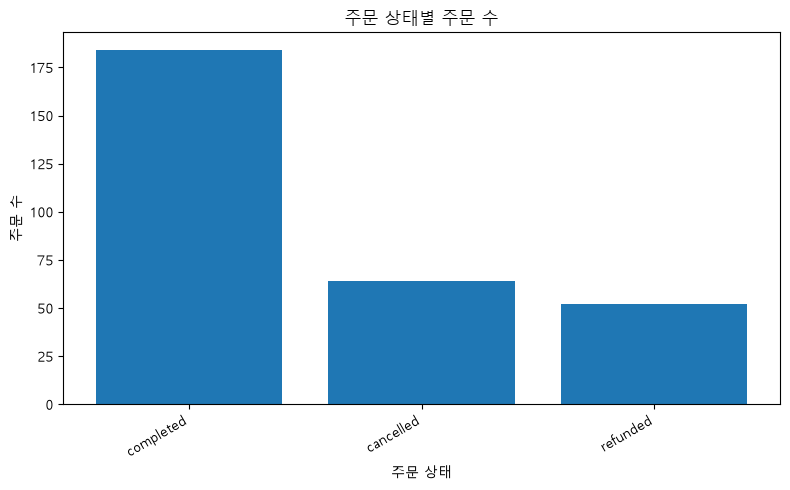

WindowsPath('c:/Users/82105/Desktop/대5/llm-data-analysis-study/llm-data-analysis-study/reports/figures/ch07_order_status_bar.png')

In [18]:
order_status_path = plot_order_status(
    order_status,
    FIGURE_DIR / "ch07_order_status_bar.png",
    show=True,
)
order_status_path

### 막대그래프 기록

- **관찰:** 전체 주문 300건 중 completed 주문이 184건으로 가장 많았고, cancelled 주문은 64건, refunded 주문은 52건으로 나타났다. 비율로 보면 완료 주문은 약 61.3%, 취소 주문은 약 21.3%, 환불 주문은 약 17.3%이다. 취소와 환불을 합하면 116건으로 전체 주문의 약 38.7%를 차지한다.

- **해석:** 전체 주문 중 완료 상태가 가장 큰 비중을 차지하지만, 취소 및 환불 주문도 일정 비중 존재한다는 것을 확인할 수 있다. 특히 취소 주문이 환불 주문보다 12건 많았다. 다만 이러한 주문 상태의 차이만으로 고객 만족도나 상품 품질에 문제가 있다고 판단할 수는 없다.

- **한계:** 현재 데이터에는 취소 사유와 환불 사유가 포함되어 있지 않기 때문에 cancelled와 refunded 주문이 발생한 원인을 확인할 수 없다. 또한 주문 상태별 건수만 비교한 것이므로 각 상태에 해당하는 구매 금액이나 상품 종류, 고객 특성의 차이도 알 수 없다. 특히 환불 주문을 상품 불만족과 직접 연결해서 해석해서는 안 된다.

- **다음 질문:** 주문 상태별 차이를 더 구체적으로 확인하기 위해 월별 취소·환불 주문 수와 비율, 카테고리별 환불 주문 수, 주문 상태별 주문 금액을 추가로 비교할 수 있다. 이를 통해 취소나 환불이 특정 기간이나 카테고리에 상대적으로 많이 나타나는지 확인해 볼 수 있다.

## 9. 그래프와 숫자를 교차 검증합니다

대표 그래프 3개 이상에 대해 다음을 확인합니다.

```text
그래프에 표시된 값
=
그래프 원본 집계표의 값
```

또한 다음을 점검합니다.

### 1. 카테고리별 완료 주문 금액 막대그래프

- 그래프에 표시된 카테고리별 완료 주문 금액과 `category_sales` 집계표의
  `completed_amount` 값을 비교한 결과 서로 일치하였다.
- 스포츠 31,743,000원, 전자기기 26,400,000원, 생활용품 23,915,000원 등
  그래프의 막대 높이와 집계값이 동일한 순서로 나타났다.
- x축은 카테고리, y축은 완료 주문 금액으로 분석 내용과 일치하며,
  금액 축은 0에서 시작해 범주 간 차이가 과장되지 않도록 하였다.
- 카테고리는 완료 주문 금액 기준 내림차순으로 정렬되어 있어 비교하기 적절하다.
- 제목도 `카테고리별 완료 주문 금액`으로 실제 분석 범위인 completed 주문을 반영하고 있다.

→ 검증 결과: 이상 없음


### 2. 월별 완료 주문 금액 선그래프

- 그래프의 각 월별 값과 `monthly_sales`의 `completed_amount`를 비교한 결과 일치하였다.
  예를 들어 2025년 10월은 25,766,000원, 2026년 1월은 17,423,000원,
  2026년 7월은 2,188,000원으로 집계표와 그래프가 동일했다.
- x축은 주문 월, y축은 완료 주문 금액으로 적절하며, 월별 데이터가
  2025-07부터 2026-07까지 시간 순서대로 정렬되어 있다.
- 월별 집계에서 제외된 날짜 결측 완료 주문 상세가 0건임을 확인하였다.
- 현재 기간에는 월이 연속적으로 존재하므로 데이터가 없는 월을 임의로 0으로
  추가한 구간은 없다.
- 제목도 `월별 완료 주문 금액 추이`로 completed 주문 기준이라는 분석 범위를 반영한다.

→ 검증 결과: 이상 없음


### 3. 상품 가격 분포 히스토그램

- 히스토그램은 `products["price"]` 원본 데이터를 사용했으며,
  상품 수는 총 100개로 확인되었다.
- 가격은 최소 5,000원에서 최대 200,000원 사이이며,
  평균은 110,040원, 중앙값은 112,000원으로 원본 요약 통계와 그래프의 범위가 일치한다.
- x축은 상품 가격, y축은 해당 가격 구간에 포함되는 상품 수로 적절하다.
- 히스토그램은 개별 금액을 그대로 막대 높이로 표시하는 그래프가 아니라
  가격 구간별 상품 수를 나타내므로 `bins` 값에 따라 막대 모양이 달라질 수 있음을 확인하였다.
- `bins=10`, `20`, `30`을 비교했으며, 세부적인 모양은 달라져도
  전체 가격 범위는 동일하게 유지되었다.
- 해당 그래프는 판매 금액이 아니라 상품 마스터의 가격 분포이므로
  completed 주문으로 제한할 필요가 없다.

→ 검증 결과: 이상 없음


### 4. 상품 가격과 완료 주문 판매 수량 산점도

- 산점도의 x축 값은 상품 가격, y축 값은 상품별 완료 주문 판매 수량이며,
  `product_sales` 집계표의 값과 일치함을 확인하였다.
- 예를 들어 가격 163,000원인 상품의 완료 주문 판매 수량은 35개,
  175,000원인 상품은 25개로 집계표와 그래프가 동일하다.
- x축과 y축 모두 0 이상에서 시작하고 있으며 축 이름도 실제 사용 변수와 일치한다.
- 상품 단위로 완료 주문 수량을 집계한 자료이므로 하나의 점은 하나의 상품을 나타낸다.
- 제목 역시 `상품 가격과 완료 주문 판매 수량의 관계`로 실제 분석 범위를 반영한다.
- 산점도에서 나타나는 관계는 두 변수의 패턴만을 보여 주며 인과관계를 의미하지 않는다.

→ 검증 결과: 이상 없음

## 10. 공통 함수로 전체 그래프와 보고서를 다시 생성합니다

Notebook에서 개별 그래프를 이해한 뒤 공통 함수를 사용해 같은 결과를 재현합니다.

In [19]:
from src.visualization import (
    build_visualization_report,
    create_all_figures,
    create_visualization_summary,
)

saved_figures = create_all_figures(viz_data, FIGURE_DIR, show=False)
summary = create_visualization_summary()

summary_path = REPORT_DIR / "ch07_visualization_summary.md"
summary_path.write_text(
    build_visualization_report(summary),
    encoding="utf-8",
)

print("생성 파일")
for path in saved_figures:
    print("-", path)

print("요약 보고서:", summary_path)
summary

생성 파일
- c:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\reports\figures\ch07_category_completed_amount_bar.png
- c:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\reports\figures\ch07_monthly_completed_amount_line.png
- c:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\reports\figures\ch07_product_price_hist.png
- c:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\reports\figures\ch07_price_completed_quantity_scatter.png
- c:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\reports\figures\ch07_top_customers_anonymized_barh.png
- c:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\reports\figures\ch07_order_status_bar.png
요약 보고서: c:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\reports\ch07_visualization_summary.md


,chart,question,scope,interpretation_point,file_name
0,카테고리별 완료 주문 금액,카테고리별 완료 주문 금액은 어떻게 다른가?,completed orders,금액 차이는 수량·단가 등 추가 지표로 확인,ch07_category_completed_amount_bar.png
1,월별 완료 주문 금액,월별 완료 주문 금액은 어떻게 변하는가?,completed orders + valid order_date,증감은 관찰이며 원인은 추가 데이터 필요,ch07_monthly_completed_amount_line.png
2,상품 가격 분포,상품 가격은 어떤 구간에 몰려 있는가?,product master,상품 구성 분포이며 판매 선호를 의미하지 않음,ch07_product_price_hist.png
3,상품 가격과 완료 주문 판매 수량,상품 가격과 완료 주문 판매 수량은 어떤 패턴을 보이는가?,completed orders aggregated by product,관계는 인과를 의미하지 않음,ch07_price_completed_quantity_scatter.png
4,완료 주문 구매 금액 상위 고객,완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가?,completed orders aggregated by customer,Top N이며 충성도를 자동 의미하지 않음,ch07_top_customers_anonymized_barh.png
5,주문 상태별 주문 수,주문 상태별 주문 수는 어떻게 다른가?,all orders,상태 분포만으로 취소·환불 원인을 알 수 없음,ch07_order_status_bar.png


### 실습

## 1. 시각화 질문과 그래프 선택
| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| 고객 거주 도시별 completed 주문의 총 구매 금액은 어떻게 다른가? | 막대그래프 | 고객 거주 도시는 범주형 변수이므로 도시별 완료 주문 총 구매 금액의 크기를 비교하기에 막대그래프가 적합하다. |
| 월별·카테고리별 completed 주문 판매 금액은 어떻게 변화하는가? | 선그래프 | 월은 시간 순서가 있는 변수이므로 시간에 따른 판매 금액의 변화를 확인하기에 선그래프가 적합하다. 카테고리별 선을 함께 표시하면 카테고리별 변화 차이도 비교할 수 있다. |
| 고객 연령과 고객별 completed 주문 총 구매 금액 사이에는 어떤 관계가 있는가? | 산점도 | 고객 연령과 총 구매 금액은 모두 수치형 변수이므로 두 변수 사이에 나타나는 관계나 분포를 확인하기 위해 산점도가 적합하다. |

+ LLM 도움 과정

![질문과 그래프 선택](images/step01_question_chart.png)

In [25]:
# 1. 고객 거주 도시별 completed 주문 총 구매 금액

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 고객 정보 결합
city_sales_data = completed_order_sales.merge(
    viz_data["customers"][["customer_id", "city"]],
    on="customer_id",
    how="left",
    validate="many_to_one",
)

# 도시별 completed 주문 금액 집계
city_sales = (
    city_sales_data
    .groupby("city", as_index=False, dropna=False)
    .agg(
        completed_order_count=("order_id", "nunique"),
        completed_amount=("line_total", "sum"),
    )
    .sort_values("completed_amount", ascending=False)
)

display(city_sales)

,city,completed_order_count,completed_amount
6,성남,31,24099000
0,고양,18,19116000
5,서울,29,19097000
8,울산,20,15380000
1,광주,17,14264000
4,부산,13,13604000
9,인천,18,12832000
3,대전,14,11792000
7,수원,14,10620000
2,대구,10,8186000


In [26]:
print(
    "원본 completed 주문 총액:",
    f'{completed_order_sales["line_total"].sum():,.0f}원'
)

print(
    "도시별 completed 주문 총액:",
    f'{city_sales["completed_amount"].sum():,.0f}원'
)

print(
    "총합 일치:",
    completed_order_sales["line_total"].sum()
    == city_sales["completed_amount"].sum()
)

원본 completed 주문 총액: 148,990,000원
도시별 completed 주문 총액: 148,990,000원
총합 일치: True


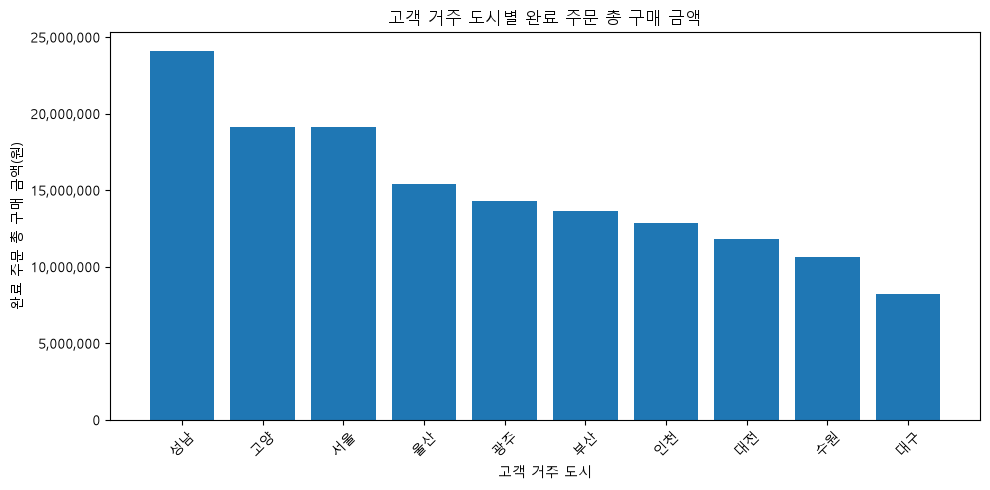

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    city_sales["city"],
    city_sales["completed_amount"],
)

ax.set_title("고객 거주 도시별 완료 주문 총 구매 금액")
ax.set_xlabel("고객 거주 도시")
ax.set_ylabel("완료 주문 총 구매 금액(원)")
ax.set_ylim(bottom=0)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value:,.0f}")
)

ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 2. 대표 그래프 1

### 원본 집계값

고객 거주 도시별 completed 주문의 총 구매 금액을 집계한 결과, 성남이 24,099,000원으로 가장 높았고, 고양 19,116,000원, 서울 19,097,000원 순으로 나타났다. 반면 대구는 8,186,000원으로 가장 낮았다.
또한 원본 completed 주문 총액과 도시별 집계 금액의 합계를 비교한 결과 모두 148,990,000원으로 동일했으며, 집계 결과가 원본 데이터와 일치함을 확인하였다.

### 결과 관찰

도시별 완료 주문 총 구매 금액에는 비교적 뚜렷한 차이가 나타났다. 성남의 구매 금액이 가장 높았고, 고양과 서울이 비슷한 수준으로 그 뒤를 이었다. 대구의 구매 금액은 다른 도시와 비교해 가장 낮게 나타났다.
완료 주문 건수도 성남이 31건으로 가장 많았으며 서울은 29건이었다. 다만 고양은 완료 주문이 18건임에도 총 구매 금액이 19,116,000원으로 서울과 거의 비슷하게 나타났다.

### 나의 해석과 판단

도시별 총 구매 금액의 차이는 단순히 주문 건수만으로 설명되지는 않는 것으로 보인다. 예를 들어 고양은 서울보다 완료 주문 건수가 적지만 총 구매 금액은 거의 같은 수준이므로, 주문 1건당 구매 금액이나 구매한 상품의 가격 차이가 함께 영향을 주었을 가능성이 있다.
따라서 성남의 총 구매 금액이 가장 높다는 사실은 확인할 수 있지만, 이를 성남 고객의 구매 성향이나 구매력이 더 높다고 단정하기는 어렵다.

### 업무·분석적 의미

도시별 매출 기여 규모를 파악하면 지역별 고객 특성을 추가로 분석할 대상을 선정하는 데 활용할 수 있다. 특히 총 구매 금액뿐 아니라 주문 수와 평균 주문 금액을 함께 비교하면 지역별 구매 패턴의 차이를 보다 구체적으로 확인할 수 있다.

### 한계와 추가 확인 사항

현재 그래프는 도시별 총 구매 금액만 비교하므로 도시별 고객 수 차이, 주문당 평균 구매 금액, 고객 1인당 구매 금액을 반영하지 않는다. 따라서 도시별 고객수와 함께 완료 주문 건수, 평균 주문 금액, 고객 1인당 평균 구매 금액을 확인할 수 있을 것이다.

In [28]:
# 2. 월별 & 카테고리별 completed 주문 판매 금액

completed_sales_items = viz_data["completed_sales_items"]

monthly_category_sales = (
    completed_sales_items
    .dropna(subset=["order_date"])
    .assign(
        order_month=lambda df: df["order_date"].dt.to_period("M")
    )
    .groupby(
        ["order_month", "category"],
        as_index=False,
    )
    .agg(
        completed_amount=("line_total", "sum")
    )
    .sort_values(
        ["order_month", "category"]
    )
)

monthly_category_sales["month_start"] = (
    monthly_category_sales["order_month"].dt.to_timestamp()
)

monthly_category_sales

,order_month,category,completed_amount,month_start
0,2025-07,도서,656000,2025-07-01
1,2025-07,뷰티,1336000,2025-07-01
2,2025-07,생활용품,1117000,2025-07-01
3,2025-07,스포츠,432000,2025-07-01
4,2025-07,전자기기,2328000,2025-07-01
...,...,...,...,...
78,2026-07,도서,342000,2026-07-01
79,2026-07,생활용품,560000,2026-07-01
80,2026-07,스포츠,218000,2026-07-01
81,2026-07,식품,923000,2026-07-01


In [29]:
print(
    "원본 completed 주문 총액:",
    f'{completed_order_sales["line_total"].sum():,.0f}원'
)

print(
    "월별·카테고리별 총액:",
    f'{monthly_category_sales["completed_amount"].sum():,.0f}원'
)

print(
    "총합 일치:",
    completed_order_sales["line_total"].sum()
    == monthly_category_sales["completed_amount"].sum()
)

원본 completed 주문 총액: 148,990,000원
월별·카테고리별 총액: 148,990,000원
총합 일치: True


In [30]:
print(
    "월 정렬 여부:",
    monthly_category_sales["order_month"].is_monotonic_increasing
)

print(
    "날짜 결측 완료 주문 상세:",
    len(viz_data["invalid_date_sales"])
)

월 정렬 여부: True
날짜 결측 완료 주문 상세: 0


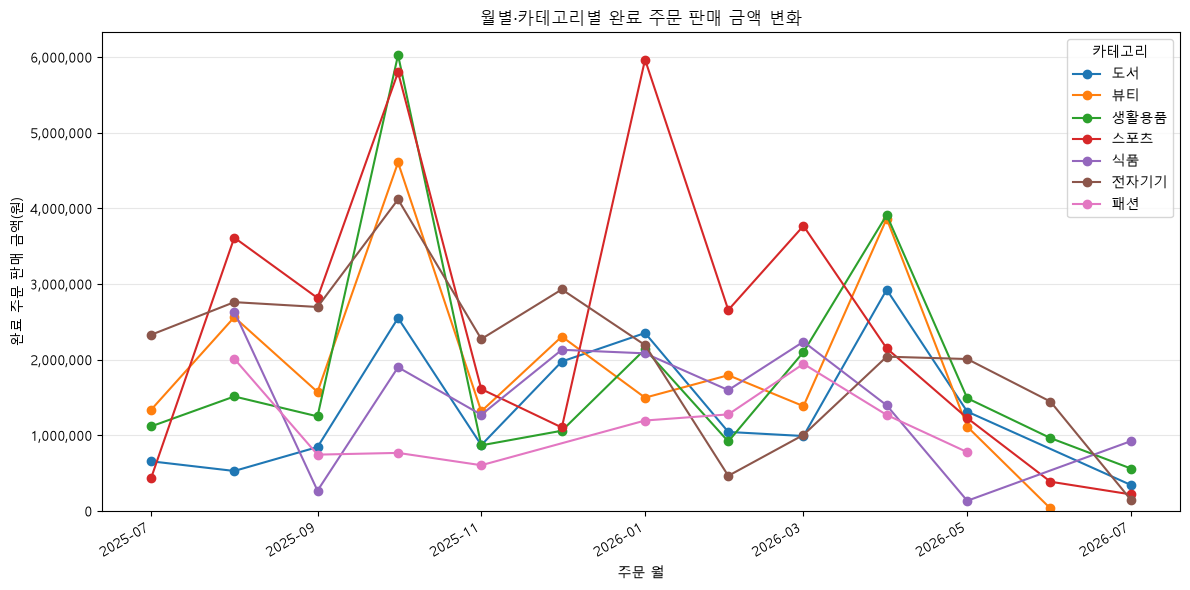

In [31]:
fig, ax = plt.subplots(figsize=(12, 6))

for category, group in monthly_category_sales.groupby(
    "category"
):
    ax.plot(
        group["month_start"],
        group["completed_amount"],
        marker="o",
        label=category,
    )

ax.set_title("월별·카테고리별 완료 주문 판매 금액 변화")
ax.set_xlabel("주문 월")
ax.set_ylabel("완료 주문 판매 금액(원)")
ax.set_ylim(bottom=0)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value:,.0f}")
)

ax.grid(axis="y", alpha=0.3)
ax.legend(title="카테고리")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 3. 대표 그래프 2

### 원본 집계값

2025년 7월부터 2026년 7월까지 월별·카테고리별 completed 주문 판매 금액을 집계하였다.
월별·카테고리별 집계 금액의 합계는 148,990,000원으로 원본 completed 주문 총액 148,990,000원과 동일하였다. 또한 월 정렬 여부는 True로 확인되었으며, 날짜 결측으로 월별 집계에서 제외된 완료 주문 상세 데이터는 0건이었다.

### 결과 관찰

카테고리별 판매 금액은 월마다 일정하게 증가하거나 감소하기보다는 변동하는 모습을 보였다.
특히 2025년 10월에는 생활용품과 스포츠 등의 카테고리 판매 금액이 크게 증가했으며, 2026년 1월에는 스포츠의 판매 금액이 약 600만 원 수준으로 크게 나타났다. 2026년 4월에는 뷰티와 생활용품의 판매 금액이 상대적으로 높게 나타났다.
반면 2026년 6월과 7월에는 여러 카테고리의 판매 금액이 이전 달보다 낮은 수준을 보였다.

### 나의 해석과 판단

전체 월별 판매 금액의 변화는 하나의 카테고리가 항상 주도하기보다는 시점에 따라 다른 카테고리의 판매 금액이 높아지면서 나타나는 것으로 보인다.
예를 들어 특정 월에는 스포츠가 높은 금액을 기록하고, 다른 월에는 생활용품이나 뷰티가 높은 금액을 기록하였다. 따라서 월별 전체 매출 변동을 이해하려면 전체 금액뿐 아니라 카테고리 구성도 함께 확인하는 것이 필요하다.
다만 이러한 변화가 계절성이나 프로모션 등의 영향 때문이라고 현재 데이터만으로 단정할 수는 없다.

### 업무·분석적 의미

월별 매출 변동이 어떤 카테고리와 함께 나타나는지를 확인하면 전체 매출 변화의 구성 요소를 파악할 수 있다. 특정 월에 크게 증가하거나 감소한 카테고리를 찾아 추가 분석 대상으로 선정하는 데 활용할 수 있다.
예를 들어 특정 카테고리의 판매 금액이 급증한 월을 대상으로 판매 수량, 주문 수, 평균 상품 가격 등을 함께 확인할 수 있다.

### 한계와 추가 확인 사항

현재 데이터에는 프로모션, 할인, 광고, 재고, 계절성 등의 정보가 없으므로 월별 변화의 원인을 직접 확인할 수 없다.
또한 특정 월·카테고리 조합이 그래프에 나타나지 않는 경우 실제 판매가 0이었던 것인지, 해당 조합의 데이터가 존재하지 않았던 것인지 구분하여 해석해야 한다. 따라서 월별&카테고리별 판매 수량, 주문 수, 평균 주문 금액, 특정 월의 판매 증가가 일부 상품에 집중되었는지 여부를 함께 확인하면 그래프 이해에 더욱 효과적일 것이다. 

In [32]:
# 3. 고객 연령과 completed 주문 총 구매 금액

age_customer_sales = customer_sales.merge(
    viz_data["customers"][["customer_id", "age"]],
    on="customer_id",
    how="left",
    validate="one_to_one",
)

age_customer_sales["age"] = pd.to_numeric(
    age_customer_sales["age"],
    errors="coerce",
)

age_customer_sales[
    [
        "customer_id",
        "age",
        "completed_order_count",
        "completed_amount",
        "average_completed_order_amount",
    ]
].head(10)

,customer_id,age,completed_order_count,completed_amount,average_completed_order_amount
0,117,65,5,4100000,820000.0
1,102,60,4,3996000,999000.0
2,83,22,4,3880000,970000.0
3,30,32,5,3590000,718000.0
4,40,23,4,3523000,880750.0
5,20,20,2,3191000,1595500.0
6,3,61,2,3178000,1589000.0
7,111,41,3,3153000,1051000.0
8,66,39,4,3093000,773250.0
9,147,19,2,2990000,1495000.0


In [33]:
print("연령 결측 고객 수:", age_customer_sales["age"].isna().sum())

print(
    "고객별 completed 금액 총합:",
    f'{age_customer_sales["completed_amount"].sum():,.0f}원'
)

print(
    "원본 completed 주문 총합:",
    f'{completed_order_sales["line_total"].sum():,.0f}원'
)

연령 결측 고객 수: 0
고객별 completed 금액 총합: 148,990,000원
원본 completed 주문 총합: 148,990,000원


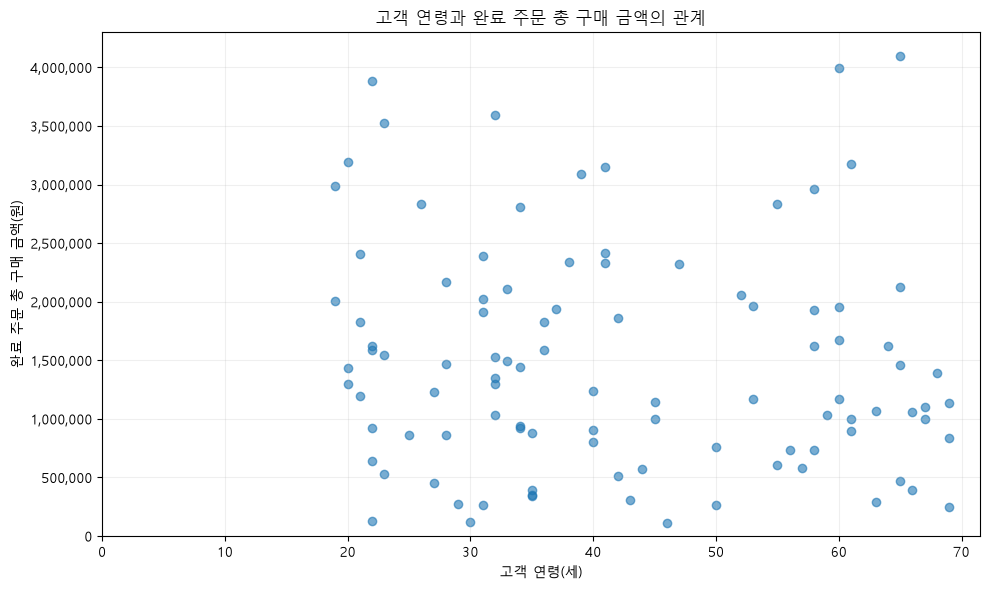

In [34]:
age_customer_plot = age_customer_sales.dropna(
    subset=["age", "completed_amount"]
).copy()

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    age_customer_plot["age"],
    age_customer_plot["completed_amount"],
    alpha=0.6,
)

ax.set_title("고객 연령과 완료 주문 총 구매 금액의 관계")
ax.set_xlabel("고객 연령(세)")
ax.set_ylabel("완료 주문 총 구매 금액(원)")

ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value:,.0f}")
)

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## 4. 대표 그래프 3

### 원본 집계값

고객별 completed 주문 총 구매 금액을 집계한 뒤 고객 연령 정보를 결합하였다.
연령 결측 고객은 0명이었으며, 고객별 완료 주문 금액의 합계는 148,990,000원으로 원본 completed 주문 총액과 동일하게 나타났다.
고객별 구매 금액은 약 10만 원 수준부터 400만 원 이상까지 넓게 분포하고 있으며, 분석 대상 고객의 연령도 약 20세부터 69세까지 넓게 분포하였다.

### 결과 관찰

산점도에서 고객 연령과 완료 주문 총 구매 금액 사이에 뚜렷한 직선 형태의 관계는 보이지 않았다.
20대에서도 300만~390만 원 수준의 높은 구매 금액을 가진 고객이 존재했으며, 60대에서도 400만 원 이상을 구매한 고객과 100만 원 이하를 구매한 고객이 함께 나타났다.
즉, 비슷한 연령에서도 고객별 총 구매 금액의 차이가 크게 나타났다.

### 나의 해석과 판단

현재 산점도만 보면 연령이 높아질수록 구매 금액이 일정하게 증가하거나 감소한다고 보기는 어렵다.
동일한 연령대에서도 구매 금액의 편차가 크기 때문에 고객의 구매 금액은 연령 외에도 주문 횟수, 주문당 구매 금액, 구매 상품의 가격 및 카테고리 등 여러 요인의 영향을 받을 가능성이 있다.
따라서 연령이 구매 금액의 직접적인 원인이라고 판단해서는 안 된다.

### 업무·분석적 의미

연령만으로 고객의 구매 규모를 구분하기에는 한계가 있다는 점을 확인할 수 있다. 따라서 고객 세분화나 구매 패턴 분석에서는 연령 단독 기준보다는 주문 빈도, 평균 주문 금액, 총 구매 금액 등의 행동 지표를 함께 활용하는 것이 더 적절할 수 있다.

### 한계와 추가 확인 사항

현재 그래프에서는 고객별 누적 구매 기간이나 가입 시점이 고려되지 않았다. 오래 가입한 고객은 자연스럽게 누적 구매 금액이 높아질 가능성이 있으므로 단순 누적 금액만으로 비교하는 데 한계가 있다.
또한 주문 횟수와 평균 주문 금액을 분리해서 보지 않았기 때문에 높은 구매 금액이 반복 주문 때문인지 일부 고액 주문 때문인지 알 수 없다. 
따라서 연령과 완료 주문 횟수나 평균 주문 금액 간의 관계를 확인하거나 연령대별 고객 수, 고객 가입 기간을 고려한 구매 금액, 연령대별 구매 카테고리 차이를 함께 해석할 수 있다. 

## 5. 그래프 정확성 점검
- [O] 그래프 값과 집계표 값 일치
- [O] 축 이름 확인
- [O] 단위 확인
- [O] 범례 확인
- [O] 날짜 정렬 확인
- [O] 과장될 수 있는 축 범위 확인
- [O] 제목이 분석 범위를 정확히 표현

### 내가 발견한 시각화 위험 또는 개선점

첫 번째 막대그래프는 금액 축이 0부터 시작하므로 도시 간 차이를 과도하게 확대하지 않고 있으며, 완료 주문 금액 기준으로 내림차순 정렬되어 있어 비교가 쉽다. 다만 도시별 고객 수가 서로 다르기 때문에 총 구매 금액만으로 도시별 고객의 구매 성향을 비교하면 오해가 발생할 수 있다.
두 번째 선그래프는 7개 카테고리의 선을 한 그래프에 표시하고 있어 일부 구간에서는 선이 겹쳐 가독성이 떨어질 수 있다. 카테고리 수가 많아질 경우 주요 카테고리만 표시하거나 카테고리별 그래프를 분리하는 방법도 고려할 수 있다. 또한 데이터가 없는 월·카테고리 조합을 자동으로 0으로 처리하지 않았다는 점을 해석할 때 주의해야 한다.
세 번째 산점도는 연령과 구매 금액의 전체 분포를 확인하기에는 적절하지만, 같은 연령의 고객이 겹쳐 표시될 수 있고 고객별 주문 횟수 차이가 그래프에 직접 나타나지 않는다. 향후 주문 횟수를 추가 변수로 활용하거나 연령대별 분포를 추가로 비교하면 해석을 보완할 수 있다.
세 그래프 모두 completed 주문 금액을 사용하는 경우 원본 총액과 집계 총액이 148,990,000원으로 일치함을 확인한 뒤 시각화를 진행하였다.


## 11. Chapter 07 최종 판단

아래 내용을 직접 작성합니다.

### 가장 중요한 그래프 1개와 이유

세 그래프 중 월별·카테고리별 완료 주문 판매 금액 변화 그래프가 가장 중요하다고 판단하였다.
이 그래프는 전체 매출의 시간적 변화뿐 아니라 월별 변화가 어떤 카테고리와 함께 나타나는지를 동시에 확인할 수 있기 때문이다. 단순 월별 총액 그래프보다 매출 변화의 구성을 한 단계 더 구체적으로 살펴볼 수 있다는 장점이 있다.

### 그래프에서 직접 확인한 사실

카테고리별 판매 금액은 분석 기간 동안 일정한 방향으로 증가하거나 감소하지 않고 월마다 변동하였다.
특정 카테고리가 분석 기간 전체에서 항상 가장 높은 판매 금액을 기록한 것은 아니었으며, 시점에 따라 스포츠, 생활용품, 뷰티 등 서로 다른 카테고리의 판매 금액이 크게 나타났다.
따라서 월별 전체 판매 금액 변화에는 카테고리별 판매 구성의 변화가 함께 나타나고 있음을 확인할 수 있었다.

### 내가 해석한 내용

월별·카테고리별 완료 주문 판매 금액은 일정한 방향으로 증가하거나 감소하기보다 월마다 변동하는 모습을 보였다. 또한 특정 카테고리가 모든 기간에서 항상 높은 판매 금액을 기록한 것은 아니었으며, 시점에 따라 스포츠, 생활용품, 뷰티 등 서로 다른 카테고리의 판매 금액이 상대적으로 높게 나타났다.

따라서 월별 전체 판매 금액의 변화는 하나의 카테고리만으로 설명하기보다, 각 월의 카테고리별 판매 구성 변화와 함께 살펴볼 필요가 있다고 판단하였다. 다만 이러한 패턴은 판매 금액의 변화를 보여 주는 것이며, 변화가 발생한 원인까지 설명하는 것은 아니다.

### 그래프만으로 말할 수 없는 것

그래프만으로는 특정 월 또는 카테고리의 판매 금액이 증가하거나 감소한 원인을 확인할 수 없다.
프로모션, 할인, 계절성, 광고, 재고 변화, 신상품 출시와 같은 정보가 현재 데이터에 포함되어 있지 않기 때문에 이러한 요인을 원인으로 단정할 수 없다.
또한 판매 금액이 높은 것이 판매 수량이 많았기 때문인지, 고가 상품이 많이 판매되었기 때문인지도 금액 그래프만으로는 알 수 없다.

### 오해를 줄이기 위해 수정하거나 확인한 요소
- 축:
  x축은 주문 월, y축은 완료 주문 판매 금액으로 설정하여 그래프에서 비교하는 변수가 명확하게 드러나도록 하였다. 금액을 비교하는 그래프의 y축은 0부터 시작하도록 설정하여 차이가 실제보다 크게 보이지 않도록 하였다.

- 단위:
  판매 금액의 단위를 원(원화)으로 명시하였다. 축의 숫자에는 천 단위 구분기호를 적용하여 실제 금액의 크기를 쉽게 확인할 수 있도록 하였다.

- 정렬:
  월별 데이터가 2025년 7월부터 2026년 7월까지 실제 시간 순서대로 정렬되어 있는지 확인하였으며, `월 정렬 여부: True`로 검증하였다.

- 범위:
  분석 범위를 전체 주문이 아닌 `order_status == "completed"`인 완료 주문으로 제한하였다. 원본 완료 주문 총액 148,990,000원과 월별·카테고리별 집계 총액 148,990,000원이 일치하는 것도 확인하였다. 또한 날짜 결측으로 월별 집계에서 제외된 완료 주문 상세는 0건이었다.

- 개인정보:
  월별·카테고리별 그래프에는 고객 이름, 고객 ID 등 개인을 식별할 수 있는 정보가 포함되지 않는다. 고객 연령 산점도에서도 개별 고객의 이름이나 ID를 그래프에 직접 표시하지 않아 불필요한 개인정보 노출을 줄였다.

### 다음 분석에서 확인하고 싶은 질문

'월별·카테고리별 판매 금액 변화는 판매 수량과 주문 건수의 변화와 어떻게 연결되는가?'
이를 위해 월별·카테고리별 판매 수량, 주문 수, 평균 주문 금액을 함께 비교하면 특정 기간의 판매 금액 변화가 주문 증가 때문인지, 판매 수량 증가 때문인지, 혹은 고가 상품 판매 때문인지 보다 구체적으로 분석할 수 있다.

---

## 완료 체크

- [O] 질문을 그래프보다 먼저 정했습니다.
- [O] 금액성 그래프에 `completed` 주문 범위를 적용했습니다.
- [O] 집계 검증표의 `passed`를 확인했습니다.
- [O] 대표 그래프 3개 이상을 만들었습니다.
- [O] 그래프와 원본 집계값을 교차 확인했습니다.
- [O] 축·단위·정렬·범위를 확인했습니다.
- [O] 관계를 원인으로 단정하지 않았습니다.
- [O] 고객 그래프에서 개인정보를 직접 노출하지 않았습니다.
- [O] 그래프별 관찰·해석·한계·다음 질문을 작성했습니다.
- [O] `reports/figures`와 요약 보고서가 재생성되는지 확인했습니다.

다음 Chapter 08에서는 전처리, EDA, 시각화와 보고서를 하나의 작은 분석 프로젝트로 연결합니다.

## 최종 체크
- [O] 그래프와 수치를 교차 검증했습니다.
- [O] 관찰과 해석을 구분했습니다.
- [O] 업무적 의미와 한계를 작성했습니다.
- [O] 최종 Notebook URL을 제출합니다.